# Histogram of Oriented Gradients (HOG) Feature Descriptor (NumPy Only)
**Objective:** Compute the **Histogram of Oriented Gradients (HOG)** feature descriptor and visualize the spatial orientation cells for a grayscale image purely using **NumPy**.

### Mathematical Formulation
1. **Spatial Gradients:**
   $$G_x(x, y) = I(x, y+1) - I(x, y-1), \quad G_y(x, y) = I(x+1, y) - I(x-1, y)$$
2. **Gradient Magnitude & Unsigned Orientation ($\theta \in [0^\circ, 180^\circ)$):**
   $$M(x, y) = \sqrt{G_x^2 + G_y^2}, \quad \theta(x, y) = \arctan2(G_y, G_x) \pmod{180^\circ}$$
3. **Cell Histogram & Block Normalization (L2-norm):**
   Each $8 \times 8$ pixel cell accumulates magnitude-weighted votes into $9$ orientation bins ($20^\circ$ per bin via linear interpolation), and overlapping $2 \times 2$ cell blocks are L2-normalized:
   $$\mathbf{v}_{\text{norm}} = \frac{\mathbf{v}}{\sqrt{\|\mathbf{v}\|_2^2 + \epsilon^2}}$$

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Create a 128x64 (standard Dalal-Triggs pedestrian detection aspect ratio) test image
H, W = 128, 64
img = np.zeros((H, W), dtype=np.float32)

# Draw a synthetic human/pedestrian silhouette (head, torso, arms, legs)
yy, xx = np.indices((H, W))
img[((yy - 22)**2 + (xx - 32)**2) <= 9**2] = 0.9          # Head
img[34:78, 22:42] = 0.85                                   # Torso
img[36:72, 14:20] = 0.75                                   # Left arm
img[36:72, 44:50] = 0.75                                   # Right arm
img[78:118, 23:30] = 0.8                                   # Left leg
img[78:118, 34:41] = 0.8                                   # Right leg


# 2. Pure NumPy Histogram of Oriented Gradients (HOG) Implementation
def compute_hog_numpy(
    image: np.ndarray,
    cell_size: int = 8,
    block_size: int = 2,
    num_bins: int = 9
):
    """
    Computes Dalal-Triggs HOG feature vector and cell-level orientation histograms
    using pure NumPy with bilinear orientation voting and L2 block normalization.
    """
    img_h, img_w = image.shape

    # Step 1: Compute centered finite-difference gradients Gx, Gy
    padded = np.pad(image, pad_width=1, mode="edge")
    gx = padded[1:-1, 2:] - padded[1:-1, :-2]
    gy = padded[2:, 1:-1] - padded[:-2, 1:-1]

    # Step 2: Magnitude and unsigned angle in [0, 180) degrees
    magnitude = np.sqrt(gx**2 + gy**2)
    orientation = np.rad2deg(np.arctan2(gy, gx)) % 180.0

    # Step 3: Accumulate orientation histograms per cell with linear bin interpolation
    n_cells_y = img_h // cell_size
    n_cells_x = img_w // cell_size
    bin_width = 180.0 / num_bins

    cell_hist = np.zeros((n_cells_y, n_cells_x, num_bins), dtype=np.float32)

    # Reshape magnitude and orientation into (n_cells_y, cell_size, n_cells_x, cell_size)
    mag_cells = magnitude[:n_cells_y * cell_size, :n_cells_x * cell_size].reshape(
        n_cells_y, cell_size, n_cells_x, cell_size
    ).transpose(0, 2, 1, 3)

    ori_cells = orientation[:n_cells_y * cell_size, :n_cells_x * cell_size].reshape(
        n_cells_y, cell_size, n_cells_x, cell_size
    ).transpose(0, 2, 1, 3)

    # Continuous bin index and linear split weights between adjacent bins
    bin_float = ori_cells / bin_width
    bin_low = np.floor(bin_float).astype(np.int32) % num_bins
    bin_high = (bin_low + 1) % num_bins
    weight_high = bin_float - np.floor(bin_float)
    weight_low = 1.0 - weight_high

    for b in range(num_bins):
        mask_low = (bin_low == b)
        mask_high = (bin_high == b)
        votes = np.where(mask_low, mag_cells * weight_low, 0.0) + np.where(mask_high, mag_cells * weight_high, 0.0)
        cell_hist[:, :, b] = np.sum(votes, axis=(-2, -1))

    # Step 4: Overlapping Block L2-Normalization (e.g., 2x2 cells per block, stride 1)
    n_blocks_y = n_cells_y - block_size + 1
    n_blocks_x = n_cells_x - block_size + 1
    hog_blocks = np.zeros((n_blocks_y, n_blocks_x, block_size, block_size, num_bins), dtype=np.float32)

    eps = 1e-6
    for by in range(n_blocks_y):
        for bx in range(n_blocks_x):
            block = cell_hist[by : by + block_size, bx : bx + block_size, :]
            norm = np.sqrt(np.sum(block**2) + eps**2)
            hog_blocks[by, bx] = block / norm

    hog_feature_vector = hog_blocks.ravel()
    return hog_feature_vector, cell_hist, magnitude, orientation


# Execute HOG extraction
hog_vec, cell_histograms, grad_mag, grad_ori = compute_hog_numpy(img, cell_size=8, block_size=2, num_bins=9)

print(f"Input Image Shape      : {img.shape}")
print(f"Cell Grid Shape        : {cell_histograms.shape[:2]} cells ({cell_histograms.shape[2]} bins/cell)")
print(f"Final HOG Feature Dim  : {hog_vec.shape[0]} features")

Input Image Shape      : (128, 64)
Cell Grid Shape        : (16, 8) cells (9 bins/cell)
Final HOG Feature Dim  : 3780 features


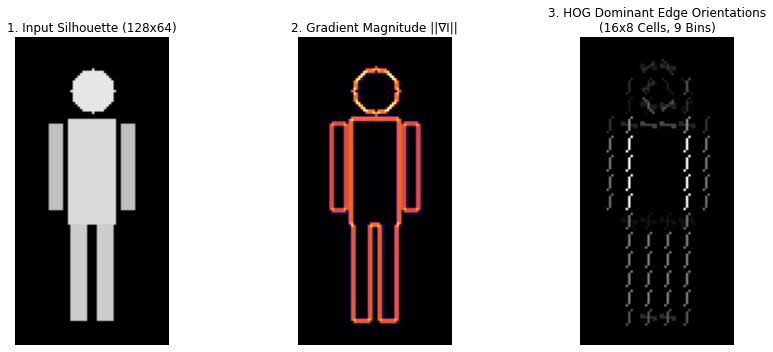

In [2]:
def render_hog_glyphs(cell_hist: np.ndarray, cell_size: int = 8) -> np.ndarray:
    """Draws oriented line segments inside each cell proportional to bin energy."""
    n_cells_y, n_cells_x, num_bins = cell_hist.shape
    canvas = np.zeros((n_cells_y * cell_size, n_cells_x * cell_size), dtype=np.float32)
    bin_angles = np.deg2rad((np.arange(num_bins) + 0.5) * (180.0 / num_bins))

    max_val = np.max(cell_hist) + 1e-8
    radius = cell_size // 2 - 1

    for cy in range(n_cells_y):
        for cx in range(n_cells_x):
            center_y = cy * cell_size + cell_size // 2
            center_x = cx * cell_size + cell_size // 2
            hist = cell_hist[cy, cx] / max_val

            for b, strength in enumerate(hist):
                if strength < 0.05:
                    continue
                # Edge direction is perpendicular (+90 deg) to gradient direction
                edge_angle = bin_angles[b] + np.pi / 2.0
                dy = np.sin(edge_angle)
                dx = np.cos(edge_angle)
                for r in range(-radius, radius + 1):
                    py = int(round(center_y + r * dy))
                    px = int(round(center_x + r * dx))
                    if 0 <= py < canvas.shape[0] and 0 <= px < canvas.shape[1]:
                        canvas[py, px] = max(canvas[py, px], float(strength))
    return canvas


hog_vis = render_hog_glyphs(cell_histograms, cell_size=8)

fig, axes = plt.subplots(1, 3, figsize=(13, 5))

axes[0].imshow(img, cmap="gray", vmin=0, vmax=1)
axes[0].set_title("1. Input Silhouette (128x64)")
axes[0].axis("off")

axes[1].imshow(grad_mag, cmap="inferno")
axes[1].set_title("2. Gradient Magnitude ||∇I||")
axes[1].axis("off")

axes[2].imshow(hog_vis, cmap="gray")
axes[2].set_title("3. HOG Dominant Edge Orientations\n(16x8 Cells, 9 Bins)")
axes[2].axis("off")

plt.tight_layout()
plt.show()